<a href="https://colab.research.google.com/github/Wrdone/MH/blob/main/%D0%9B%D0%A04_%D0%9B%D1%83%D0%BA'%D1%8F%D0%BD_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('CarPrice_Assignment.csv')

print(f"Кількість об'єктів (рядків): {df.shape[0]}, Ознак (стовпців): {df.shape[1]}")
print("\nТипи даних:\n", df.dtypes)
print("\nОсновні статистики:\n", df.describe())

Кількість об'єктів (рядків): 205, Ознак (стовпців): 26

Типи даних:
 car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
compressionratio    float64
horsepower            int64
peakrpm               int64
citympg               int64
highwaympg            int64
price               float64
dtype: object

Основні статистики:
            car_ID   symboling   wheelbase   carlength    carwidth   carheight  \
count  205.000000  205.000000  205.000000  205.000000  205.000000  205.000000   
mean 

## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [ ]:
print("Пропущені значення:\n", df.isnull().sum().sum())
print("Повні дублікати:\n", df.duplicated().sum())
print("\nКількість унікальних значень:\n", df.nunique())

Пропущені значення:
 0
Повні дублікати:
 0

Кількість унікальних значень:
 car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
carheight            49
curbweight          171
enginetype            7
cylindernumber        7
enginesize           44
fuelsystem            8
boreratio            38
stroke               37
compressionratio     32
horsepower           59
peakrpm              23
citympg              29
highwaympg           30
price               189
dtype: int64


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [ ]:
car_ids_full = df['car_ID']

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


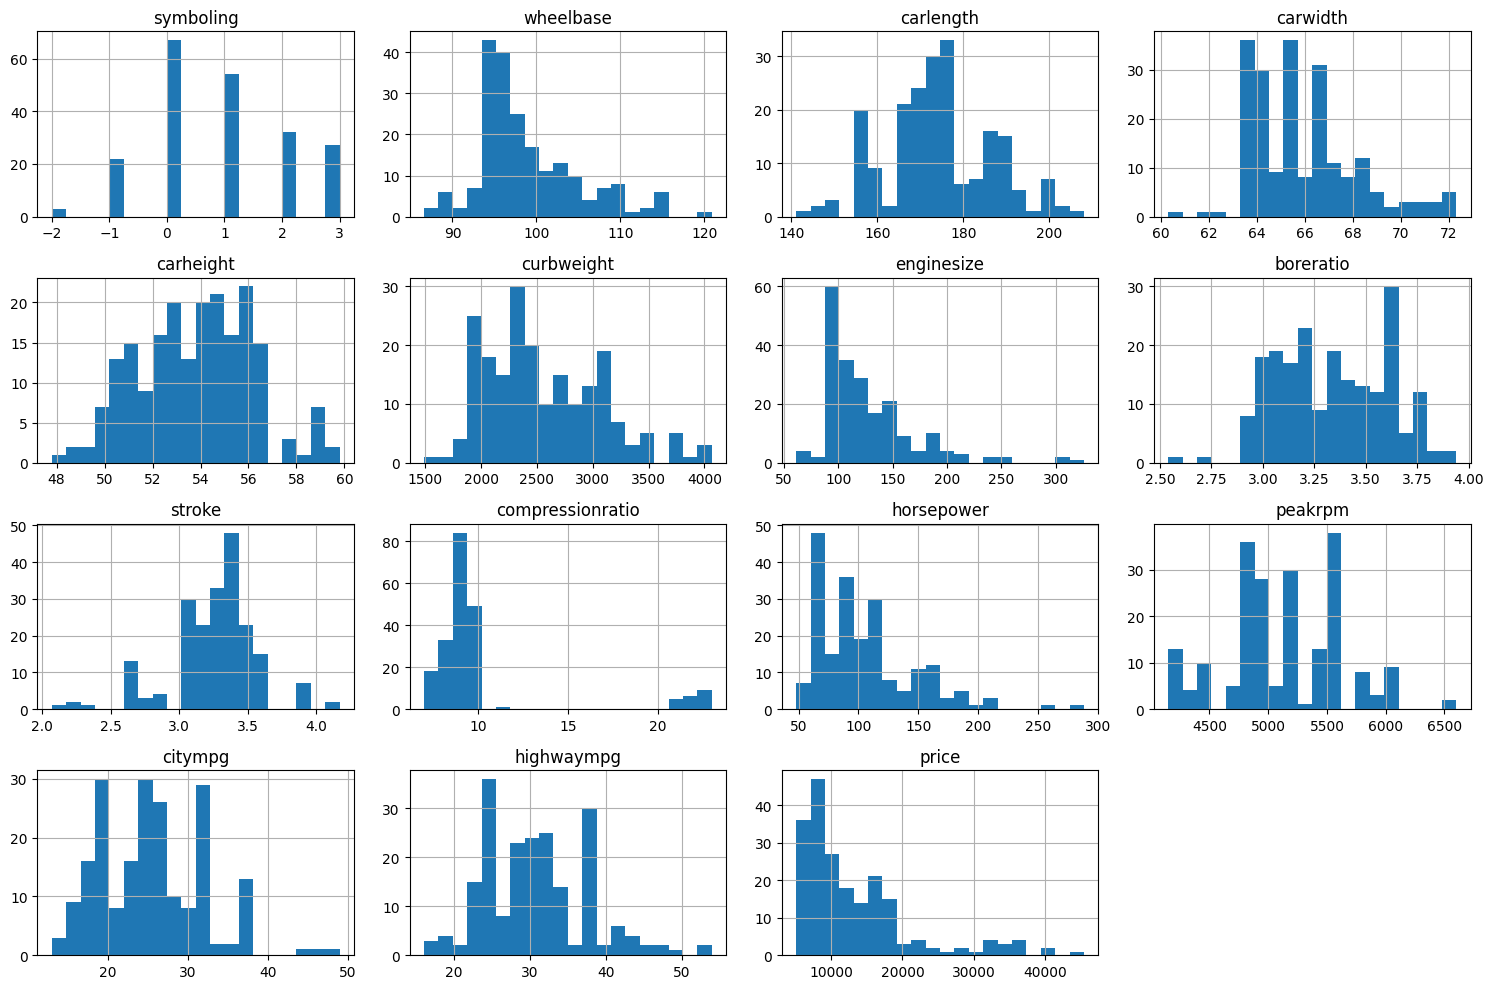

Коефіцієнти асиметрії:
 compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
carwidth            0.904003
curbweight          0.681398
citympg             0.663704
highwaympg          0.539997
symboling           0.211072
carlength           0.155954
peakrpm             0.075159
carheight           0.063123
boreratio           0.020156
stroke             -0.689705
dtype: float64


In [ ]:
num_cols = df.select_dtypes(include=np.number).drop(columns=['car_ID'])

num_cols.hist(figsize=(15, 10), bins=20)
plt.tight_layout()
plt.show()

skewness = num_cols.skew().sort_values(ascending=False)
print("Коефіцієнти асиметрії:\n", skewness)

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop('price', axis=1)
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

car_ID_train = X_train.pop('car_ID')
car_ID_test = X_test.pop('car_ID')

## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [ ]:
num_features = X_train.select_dtypes(include=np.number).columns.tolist()

for col in num_features:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers_count = ((X_train[col] < lower_bound) | (X_train[col] > upper_bound)).sum()
    print(f"{col}: {outliers_count} викидів")

    # Обмеження (clipping) значень для train та test
    X_train[col] = X_train[col].clip(lower=lower_bound, upper=upper_bound)
    X_test[col] = X_test[col].clip(lower=lower_bound, upper=upper_bound)

symboling: 0 викидів
wheelbase: 6 викидів
carlength: 0 викидів
carwidth: 10 викидів
carheight: 0 викидів
curbweight: 0 викидів
enginesize: 7 викидів
boreratio: 1 викидів
stroke: 16 викидів
compressionratio: 20 викидів
horsepower: 7 викидів
peakrpm: 2 викидів
citympg: 0 викидів
highwaympg: 1 викидів


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


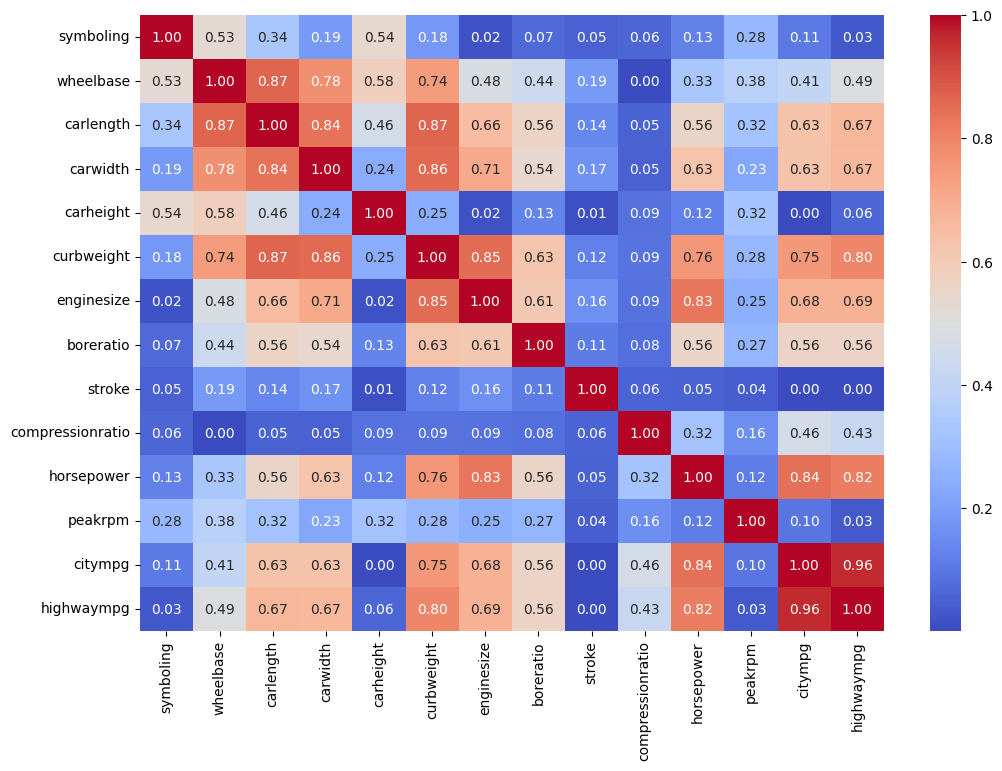

Ознаки для видалення через високу кореляцію: ['carlength', 'curbweight', 'highwaympg']


In [ ]:
corr_matrix = X_train[num_features].corr().abs()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.show()

upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.85)]

print(f"Ознаки для видалення через високу кореляцію: {to_drop}")

X_train = X_train.drop(columns=to_drop)
X_test = X_test.drop(columns=to_drop)

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PowerTransformer
from sklearn.pipeline import Pipeline

num_features = X_train.select_dtypes(include=np.number).columns.tolist()
cat_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

if 'symboling' in num_features:
    num_features.remove('symboling')

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('yeo_johnson', PowerTransformer(method='yeo-johnson')),
            ('scaler', StandardScaler())
        ]), num_features),
        ('sym', StandardScaler(), ['symboling'] if 'symboling' in X_train.columns else []),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ])

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [ ]:
pt = PowerTransformer(method='yeo-johnson')
transformed_num = pd.DataFrame(pt.fit_transform(X_train[num_features]), columns=num_features)

print(" Асиметрія до:\n", X_train[num_features].skew())
print("\n Асиметрія після:\n", transformed_num.skew())

 Асиметрія до:
 wheelbase           0.935764
carwidth            0.730804
carheight           0.028154
enginesize          0.962394
boreratio           0.062963
stroke             -0.397600
compressionratio    0.055710
horsepower          0.850735
peakrpm             0.039773
citympg             0.419117
dtype: float64

 Асиметрія після:
 wheelbase           0.020429
carwidth            0.000000
carheight          -0.005170
enginesize          0.044834
boreratio          -0.005941
stroke              0.015846
compressionratio    0.004872
horsepower          0.066280
peakrpm            -0.003589
citympg            -0.008044
dtype: float64


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Lasso': Lasso(),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'SVR': SVR()
}


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [ ]:
results = []

for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    results.append({
        'Model': name,
        'R2': r2_score(y_test, y_pred),
        'MAE': mean_absolute_error(y_test, y_pred),
        'MSE': mean_squared_error(y_test, y_pred),
        'MAPE (%)': mean_absolute_percentage_error(y_test, y_pred) * 100
    })

results_df = pd.DataFrame(results).sort_values(by='R2', ascending=False)
print(results_df)

               Model        R2          MAE           MSE   MAPE (%)
3      Random Forest  0.952913  1427.932878  3.717216e+06  10.551271
4  Gradient Boosting  0.931077  1661.611353  5.441026e+06  11.609293
1              Ridge  0.777583  2788.493494  1.755851e+07  24.396054
2              Lasso  0.706026  2996.274371  2.320750e+07  22.595397
0  Linear Regression  0.612042  3565.734825  3.062693e+07  25.635537
5                SVR -0.099818  5696.159484  8.682407e+07  36.014535


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Ціна автомобіля є неперервною числовою величиною. Класифікаційні моделі створені для передбачення обмеженої кількості категорій. Для прогнозування неперервних значень завжди використовується регресія.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


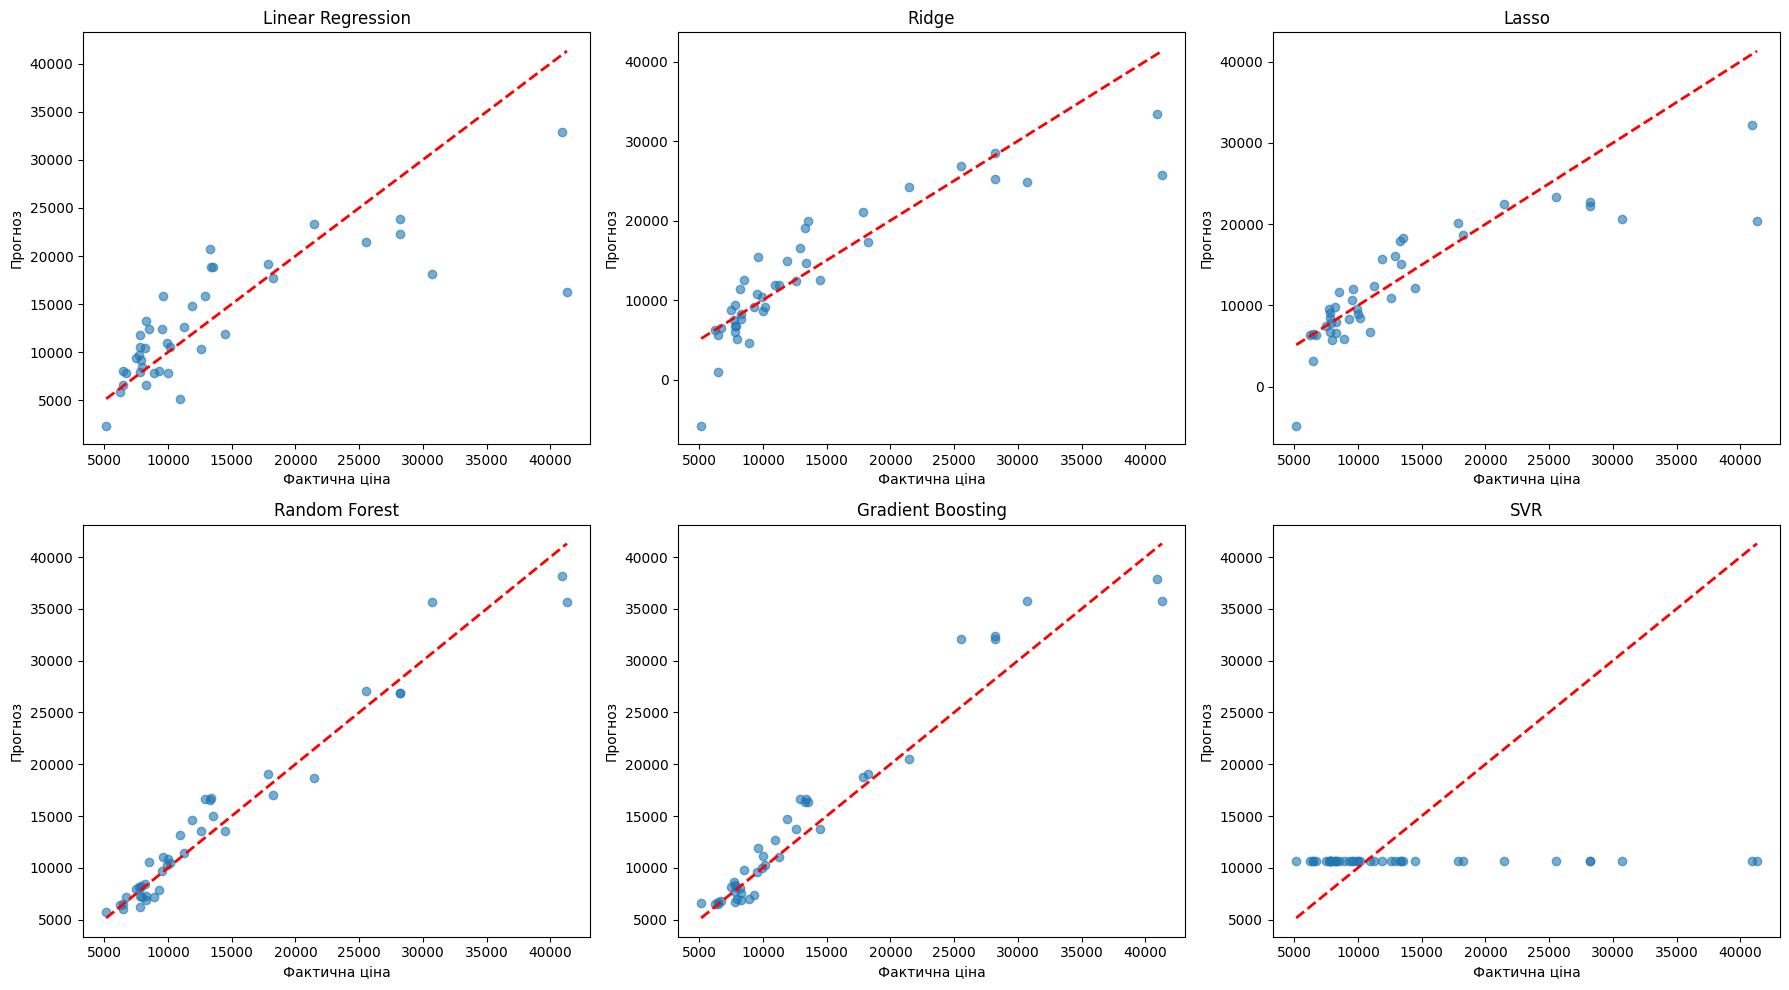

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for idx, (name, model) in enumerate(models.items()):
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', model)])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    axes[idx].scatter(y_test, y_pred, alpha=0.6)
    axes[idx].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[idx].set_title(name)
    axes[idx].set_xlabel('Фактична ціна')
    axes[idx].set_ylabel('Прогноз')

plt.tight_layout()
plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [ ]:
rf_pipeline = Pipeline([('preprocessor', preprocessor), ('regressor', RandomForestRegressor(random_state=42))])
rf_pipeline.fit(X_train, y_train)

sample_indices = X_test.sample(10, random_state=42).index
X_sample = X_test.loc[sample_indices]
y_sample_actual = y_test.loc[sample_indices]
car_id_sample = car_ID_test.loc[sample_indices]

y_sample_pred = rf_pipeline.predict(X_sample)

sample_results = pd.DataFrame({
    'car_ID': car_id_sample,
    'Фактична ціна': y_sample_actual,
    'Прогноз': y_sample_pred,
    'Абс. помилка': abs(y_sample_actual - y_sample_pred),
    'Відс. помилка (%)': abs((y_sample_actual - y_sample_pred) / y_sample_actual) * 100
})

print(sample_results)

     car_ID  Фактична ціна   Прогноз  Абс. помилка  Відс. помилка (%)
25       26         6692.0   7201.09        509.09           7.607442
175     176         9988.0  10823.11        835.11           8.361133
147     148        10198.0  10422.16        224.16           2.198078
16       17        41315.0  35695.46       5619.54          13.601694
68       69        28248.0  26911.33       1336.67           4.731910
146     147         7463.0   7995.07        532.07           7.129439
143     144         9960.0  10308.31        348.31           3.497088
84       85        14489.0  13590.58        898.42           6.200704
194     195        12940.0  16660.38       3720.38          28.751005
159     160         7788.0   7266.25        521.75           6.699409


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


За результатами виконання лабораторної роботи та побудови регресійних моделей для прогнозування цін на автомобілі можна зробити такі підсумки:   

Найкраща модель: Абсолютним лідером серед усіх протестованих алгоритмів став Random Forest, який показав найвищий коефіцієнт детермінації та найменші значення похибок. Модель Gradient Boosting також продемонструвала відмінний результат, трохи поступившись випадковому лісу.  

Аналіз метрик похибок: Для найкращої моделі (Random Forest) середня абсолютна похибка становить близько $1428, що означає, що модель в середньому помиляється на цю суму. Відносна похибка дорівнює 10.55%, що є дуже хорошим показником для задачі прогнозування цін.

Лінійні моделі:Базові лінійні моделі  впоралися із задачею значно гірше. Їхній R² коливається в межах 0.61–0.78, а відсоток помилки становить 22–25%. Регуляризація  допомогла дещо покращити результат порівняно зі звичайною лінійною регресією, але цього виявилося недостатньо, щоб наздогнати ансамблеві методи. Це свідчить про наявність складних нелінійних залежностей між характеристиками авто та їх ціною.

Модель SVR: Метод опорних векторів показав найгірший результат із від'ємним R². Це означає, що за поточних гіперпараметрів ця модель працює гірше, ніж якби ми просто завжди прогнозували середню ціну по всій вибірці.

Вплив передобробки: Незважаючи на стандартизацію ознак, усунення мультиколінеарності та застосування трансформації Yeo-Johnson для нормалізації розподілів, лінійні моделі все одно показали посередні результати. Натомість деревоподібним алгоритмам, які є менш чутливими до розподілу та масштабу ознак, вдалося виявити глибші закономірності в даних.Щодо перенавчання: Високий показник R² на тестовій вибірці (0.95) для Random Forest свідчить про те, що модель добре генералізує дані, і серйозного перенавчання не спостерігається.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
